# M2.6 · 纯因子组合与风险

> 纯因子组合（pure factor portfolio）通过截面加权回归构造，使组合在目标因子暴露为1、在其他因子暴露为0，
> 从而把单一因子的收益和风险"提纯"出来。它是因子收益估计、风险归因和对冲的基础。

## 一、原理

截面回归 r = X f + ε，加权最小二乘解：

- 因子收益 f = (X^T W X)^-1 X^T W r
- 纯因子组合权重 P = W X (X^T W X)^-1

P 的每一列是一个组合：对该因子暴露1、对其余因子暴露0，且通常市值中性（权重和为0）。


## 二、加载数据并构造因子

In [1]:
import sys, numpy as np, pandas as pd
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
from l2.config import load_universe
import config
from factor_lab2 import barra, purefactor
from factor_lab2.combine import cross_zscore
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = load_universe('hs300')
raw = D.features(codes, ['$open','$close','$high','$low','$volume',
                         '$mkt_cap_ard','$pe_ttm','$pb_lf'],
                 start_time='2018-01-01', freq='day')
cl=raw['$close'].unstack('instrument'); vo=raw['$volume'].unstack('instrument')
mk=raw['$mkt_cap_ard'].unstack('instrument')
pe=raw['$pe_ttm'].unstack('instrument'); pb=raw['$pb_lf'].unstack('instrument')
bench = pd.read_csv(config.BENCHMARK_DIR/'000300_sh.csv',
                    parse_dates=['date']).set_index('date')
bench_ret = bench['close'].pct_change(fill_method=None).reindex(cl.index).ffill()
bf = barra.build_barra(cl, vo, mk, pe, pb, bench_ret)
exnames = ['Size','Beta','Momentum','Residual Volatility','BTP']
print('因子:', exnames)

[28240:MainThread](2026-11-05 16:37:18,495) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[28240:MainThread](2026-11-05 16:37:20,616) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[28240:MainThread](2026-11-05 16:37:20,618) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


因子: ['Size', 'Beta', 'Momentum', 'Residual Volatility', 'BTP']


## 三、单截面构造纯因子组合并验证

In [2]:
dt = cl.index[-2]
X = pd.DataFrame({n: cross_zscore(bf[n]).loc[dt] for n in exnames}).dropna()
X.insert(0, 'const', 1.0)
wcap = mk.loc[dt].reindex(X.index)
P = purefactor.pure_factor_weights(X, wcap)
check = purefactor.pure_portfolio_exposure_check(X, wcap)
print('纯因子暴露矩阵（应≈单位阵）:')
print(np.round(check, 3))
print()
print('各纯因子组合权重和（应≈0，市值中性）:')
print(P.sum().round(4).to_string())

纯因子暴露矩阵（应≈单位阵）:
[[ 1.  0.  0. -0.  0.  0.]
 [ 0.  1. -0.  0.  0. -0.]
 [ 0. -0.  1. -0. -0.  0.]
 [-0.  0.  0.  1. -0. -0.]
 [ 0. -0. -0. -0.  1.  0.]
 [-0. -0.  0. -0. -0.  1.]]

各纯因子组合权重和（应≈0，市值中性）:
const                  1.0
Size                   0.0
Beta                   0.0
Momentum              -0.0
Residual Volatility   -0.0
BTP                    0.0


C:\Users\gucao\AppData\Local\Temp\ipykernel_28240\2612318758.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=exnames, showfliers=False, patch_artist=True)


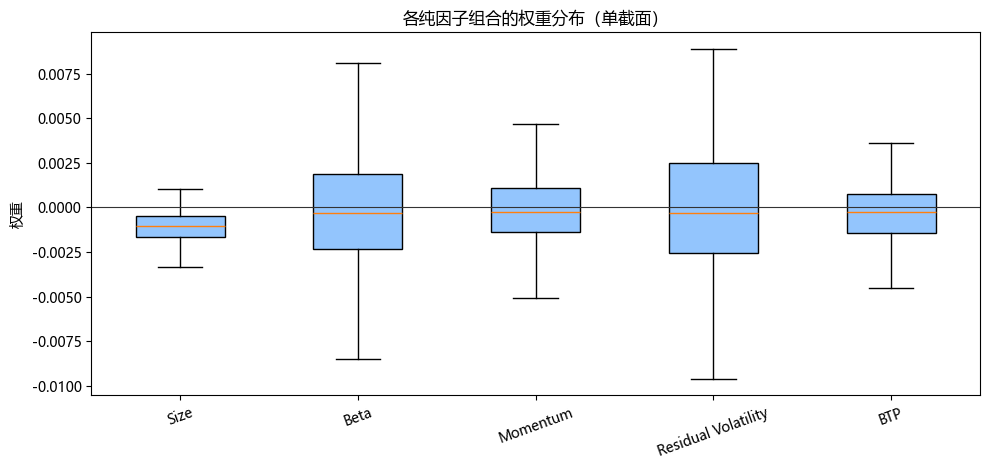

In [3]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(10,4.8))
data = [P[n].values for n in exnames]
bp = ax.boxplot(data, labels=exnames, showfliers=False, patch_artist=True)
for patch in bp['boxes']:
    patch.set_facecolor('#93c5fd')
ax.axhline(0, color='#333', lw=0.8)
ax.set_title('各纯因子组合的权重分布（单截面）'); ax.set_ylabel('权重')
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

## 四、逐截面估计因子收益与风险

In [4]:
returns = cl.pct_change(fill_method=None)
zex = {n: cross_zscore(bf[n]) for n in exnames}
fr_rows = {}; res_rows = {}
for d in returns.index:
    y = returns.loc[d]
    Xd = pd.DataFrame({n: zex[n].loc[d] for n in exnames})
    ok = y.notna() & Xd.notna().all(axis=1)
    if ok.sum() < len(exnames)+5:
        continue
    Xv = np.column_stack([np.ones(ok.sum()), Xd[ok].values])
    gamma, *_ = np.linalg.lstsq(Xv, y[ok].values, rcond=None)
    fr_rows[d] = gamma[1:]
    res_rows[d] = y[ok].values - Xv@gamma
fr = pd.DataFrame(fr_rows, index=exnames).T
print('因子收益序列:', fr.shape)
print('年化因子收益:')
print((fr.mean()*242).round(4).to_string())

因子收益序列: (565, 5)
年化因子收益:
Size                   0.1277
Beta                   0.0289
Momentum              -0.0786
Residual Volatility    0.2098
BTP                   -0.0506


In [5]:
Sigma_f = fr.cov()*242
print('因子协方差矩阵（年化）:')
print(Sigma_f.round(4).to_string())

因子协方差矩阵（年化）:
                       Size    Beta  Momentum  Residual Volatility     BTP
Size                 0.0013  0.0002    0.0003              -0.0001  0.0004
Beta                 0.0002  0.0202    0.0008               0.0011  0.0002
Momentum             0.0003  0.0008    0.0045              -0.0013  0.0005
Residual Volatility -0.0001  0.0011   -0.0013               0.0063 -0.0006
BTP                  0.0004  0.0002    0.0005              -0.0006  0.0016


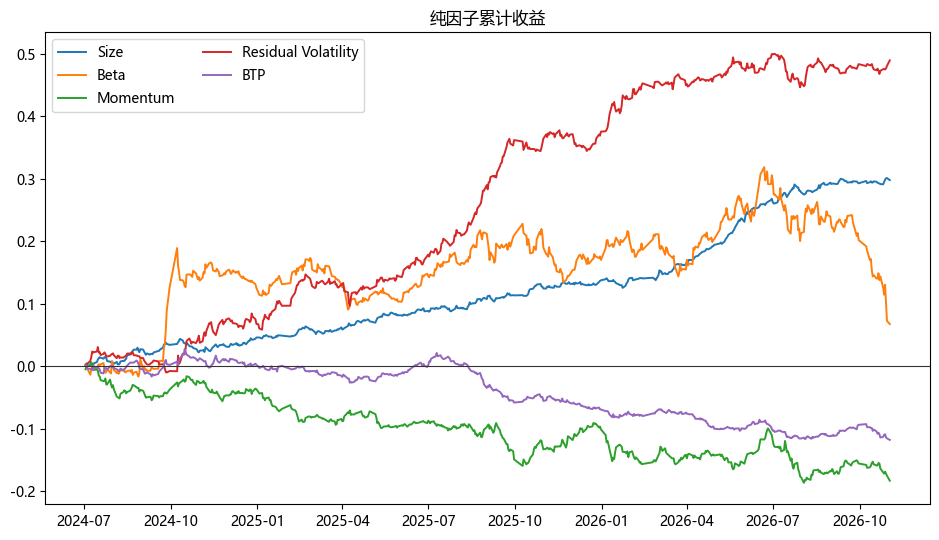

In [6]:
fig, ax = plt.subplots(figsize=(9.5,5.5))
cum = (fr.fillna(0).cumsum())
for n in exnames:
    ax.plot(cum.index, cum[n], label=n, lw=1.4)
ax.axhline(0, color='#333', lw=0.8)
ax.set_title('纯因子累计收益'); ax.legend(ncol=2)
plt.tight_layout(); plt.show()

## 五、小结与面试要点

- 纯因子组合通过加权回归构造，对目标因子暴露1、其余0、权重和为0，实现单一因子提纯。
- 因子收益逐截面估计，因子协方差刻画因子间风险，特异风险来自残差。

**面试高频：**
- 什么是纯因子组合？（答：目标因子暴露1、其他因子0、通常市值中性的组合）
- 为什么用市值加权？（答：贴近可投资性，大盘股信息更可靠，降低小盘噪声）
- 因子协方差有什么用？（答：风险预算、组合优化、因子对冲）
- 纯因子组合权重和为什么是0？（答：含截距且市值中性，多空对冲、不占用净资金）

## 动手练习
1. 构造纯因子组合并验证单位阵与权重和；
2. 画出各因子累计收益，判断哪个因子长期贡献最大；
3. 用因子协方差分析因子间的风险联动。

---
下一节 M2.7 用 Fama-MacBeth 检验因子风险溢价。